In [2]:
import matplotlib.pyplot as plt
import numpy as np

from analysis.config import FIGURES, SEED, STYLE, TABLES
from analysis.io import load_dataset

plt.style.use(STYLE)

CLASS_NAMES = ["Normal", "Suspeito", "Patológico"]
CLASS_COLORS = ["tab:blue", "tab:orange", "tab:red"]

d = load_dataset("ctg")
X, y, names = d["X_train"], d["y_train"], d["feature_names"]  # só o treino
print(X.shape, np.bincount(y))

(1755, 20) [1363  245  147]


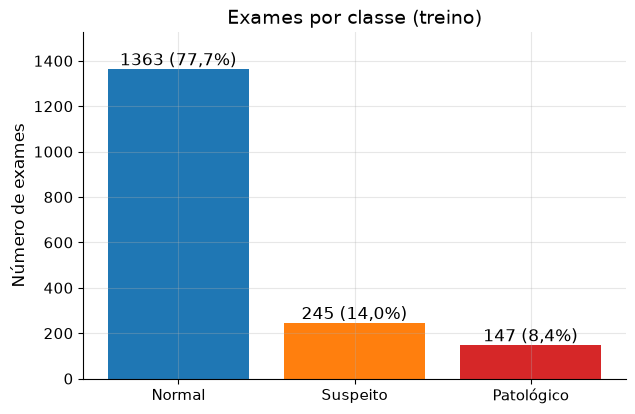

In [4]:
counts = np.bincount(y)
percentages = counts / counts.sum() * 100
labels = [
    f"{count} ({pct:.1f}%)".replace(".", ",")
    for count, pct in zip(counts, percentages)
]

fig, ax = plt.subplots()
bars = ax.bar(CLASS_NAMES, counts, color=CLASS_COLORS)
ax.bar_label(bars, labels=labels)
ax.set_ylim(0, counts.max() * 1.12)  # folga para o texto acima da barra mais alta
ax.set_ylabel("Número de exames")
ax.set_title("Exames por classe (treino)")

fig.savefig(FIGURES / "ctg_classes.png", dpi=200, bbox_inches="tight")
plt.show()

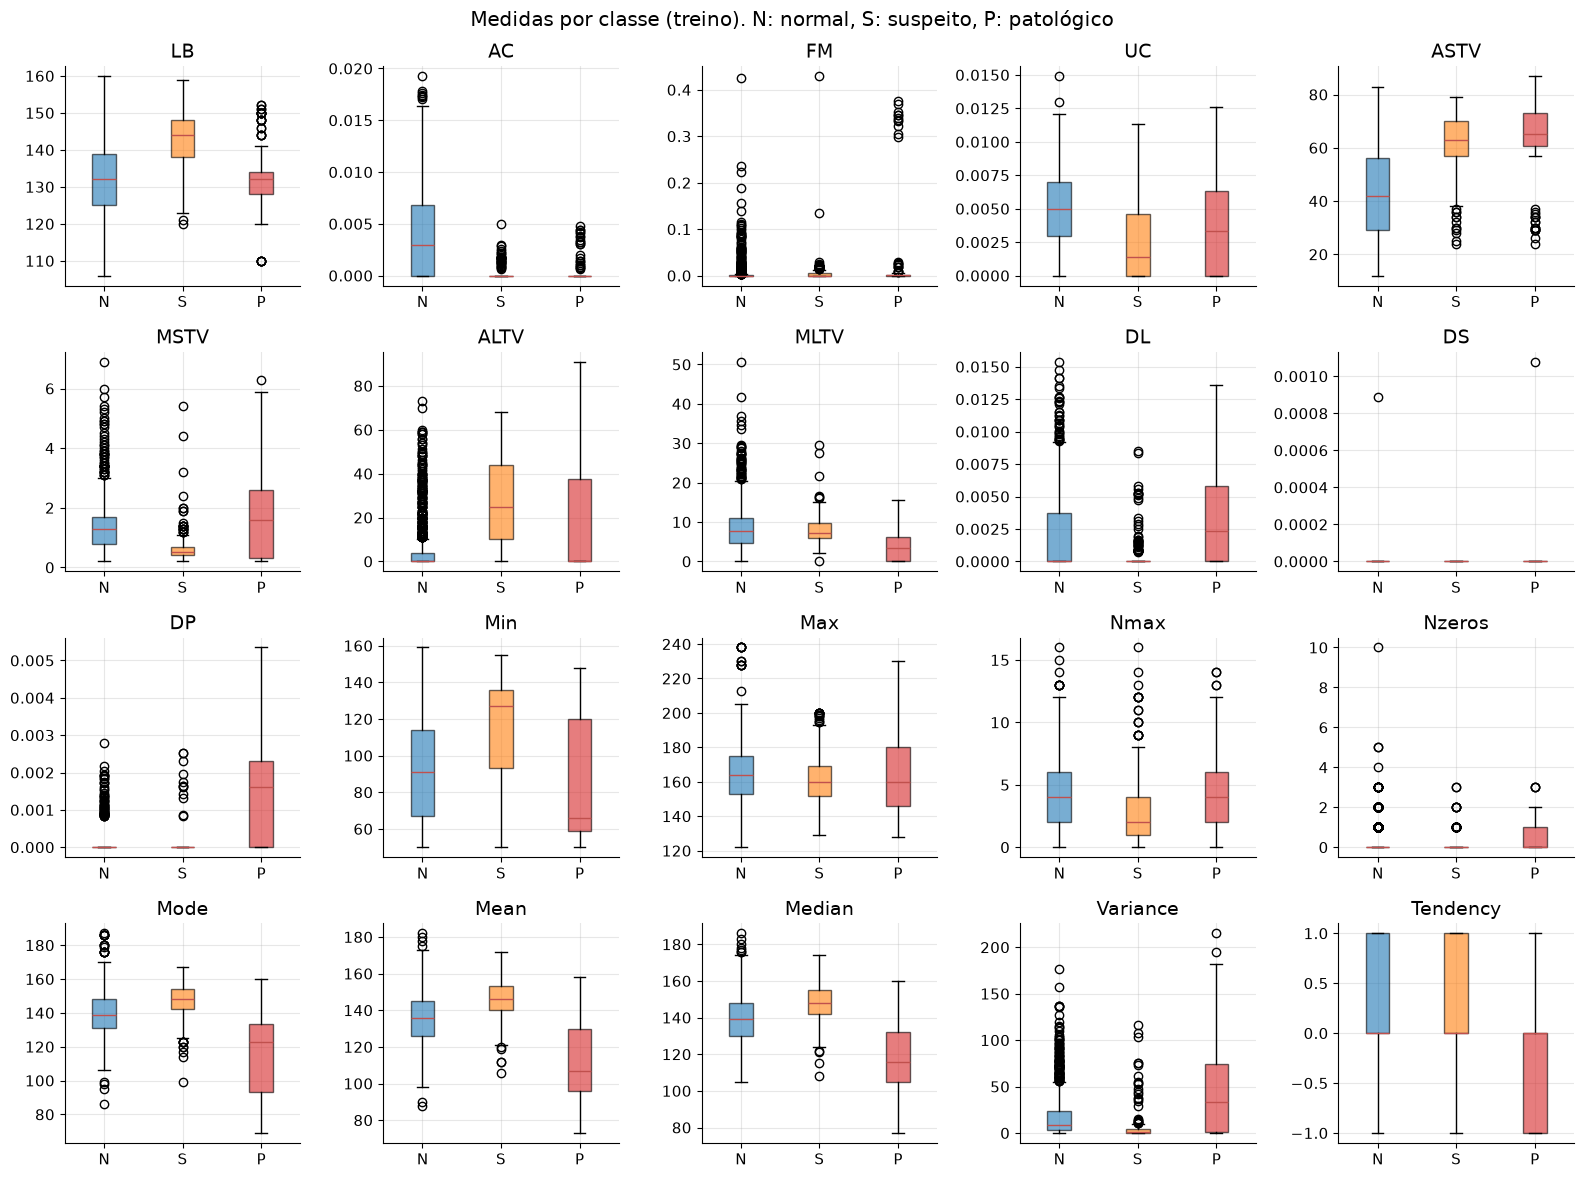

In [6]:
n_rows, n_cols = 4, 5
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 12))

for j, ax in enumerate(axes.flat):
    # valores da medida j em cada classe: uma lista com 3 arrays
    values_by_class = [X[y == k, j] for k in range(3)]
    
    box = ax.boxplot(values_by_class, patch_artist=True)
    for patch, color in zip(box["boxes"], CLASS_COLORS):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)

    ax.set_title(names[j])
    ax.set_xticks([1, 2, 3], ["N", "S", "P"])

fig.suptitle("Medidas por classe (treino). N: normal, S: suspeito, P: patológico")
fig.tight_layout()
fig.savefig(FIGURES / "ctg_boxplots.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
idx = {name: i for i, name in enumerate(names)}
for name in ["FM", "DS", "DP", "Nzeros"]:
    zeros = [(X[y == k, idx[name]] == 0).mean() for k in range(3)]
    print(name, np.round(zeros, 3))

    ds = X[:, idx["DS"]]
for k, class_name in enumerate(CLASS_NAMES):
    n_nonzero = int((ds[y == k] != 0).sum())
    print(f"DS, {class_name}: {n_nonzero} linhas diferentes de zero, "
          f"variância {ds[y == k].var():.2e}")

FM [0.668 0.539 0.476]
DS [0.999 1.    0.993]
DP [0.957 0.951 0.408]
Nzeros [0.754 0.845 0.741]
DS, Normal: 1 linhas diferentes de zero, variância 5.81e-10
DS, Suspeito: 0 linhas diferentes de zero, variância 0.00e+00
DS, Patológico: 1 linhas diferentes de zero, variância 7.86e-09
